# Exploration du Dataset COVID-19 NLP Text Classification

Ce notebook explore le dataset de tweets COVID-19 pour l'analyse de sentiment.

## 1. Importation des bibliothèques

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

print("Bibliothèques importées avec succès!")

Bibliothèques importées avec succès!


## 2. Chargement des données

In [2]:
# Charger les datasets d'entraînement et de test
train_df = pd.read_csv('Corona_NLP_train.csv', encoding='latin-1')
test_df = pd.read_csv('Corona_NLP_test.csv', encoding='latin-1')

print(f"Dataset d'entraînement: {train_df.shape[0]} tweets")
print(f"Dataset de test: {test_df.shape[0]} tweets")
print(f"Total: {train_df.shape[0] + test_df.shape[0]} tweets")

Dataset d'entraînement: 41157 tweets
Dataset de test: 3798 tweets
Total: 44955 tweets


## 3. Aperçu des données

In [3]:
# Afficher les premières lignes
print("Premières lignes du dataset:")
train_df.head()

Premières lignes du dataset:


,UserName,ScreenName,Location,TweetAt,OriginalTweet,Sentiment
0,3799,48751,London,16-03-2020,@MeNyrbie @Phil_Gahan @Chrisitv https://t.co/i...,Neutral
1,3800,48752,UK,16-03-2020,advice Talk to your neighbours family to excha...,Positive
2,3801,48753,Vagabonds,16-03-2020,Coronavirus Australia: Woolworths to give elde...,Positive
3,3802,48754,NaN,16-03-2020,My food stock is not the only one which is emp...,Positive
4,3803,48755,NaN,16-03-2020,"Me, ready to go at supermarket during the #COV...",Extremely Negative


In [4]:
# Informations sur le dataset
print("Informations sur le dataset:")
train_df.info()

Informations sur le dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41157 entries, 0 to 41156
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   UserName       41157 non-null  int64 
 1   ScreenName     41157 non-null  int64 
 2   Location       32567 non-null  object
 3   TweetAt        41157 non-null  object
 4   OriginalTweet  41157 non-null  object
 5   Sentiment      41157 non-null  object
dtypes: int64(2), object(4)
memory usage: 1.9+ MB


In [5]:
# Statistiques descriptives
print("Statistiques descriptives:")
train_df.describe()

Statistiques descriptives:


,UserName,ScreenName
count,41157.000000,41157.000000
mean,24377.000000,69329.000000
std,11881.146851,11881.146851
min,3799.000000,48751.000000
25%,14088.000000,59040.000000
50%,24377.000000,69329.000000
75%,34666.000000,79618.000000
max,44955.000000,89907.000000


## 4. Analyse des sentiments (classes)

In [6]:
# Voir toutes les classes de sentiment
print("Classes de sentiment disponibles:")
print(train_df['Sentiment'].unique())
print(f"\nNombre de classes: {train_df['Sentiment'].nunique()}")

Classes de sentiment disponibles:
['Neutral' 'Positive' 'Extremely Negative' 'Negative' 'Extremely Positive']

Nombre de classes: 5


In [7]:
# Distribution des sentiments
print("Distribution des sentiments:")
sentiment_counts = train_df['Sentiment'].value_counts()
print(sentiment_counts)
print(f"\nPourcentages:")
print(train_df['Sentiment'].value_counts(normalize=True) * 100)

Distribution des sentiments:
Sentiment
Positive              11422
Negative               9917
Neutral                7713
Extremely Positive     6624
Extremely Negative     5481
Name: count, dtype: int64

Pourcentages:
Sentiment
Positive              27.752266
Negative              24.095537
Neutral               18.740433
Extremely Positive    16.094468
Extremely Negative    13.317297
Name: proportion, dtype: float64


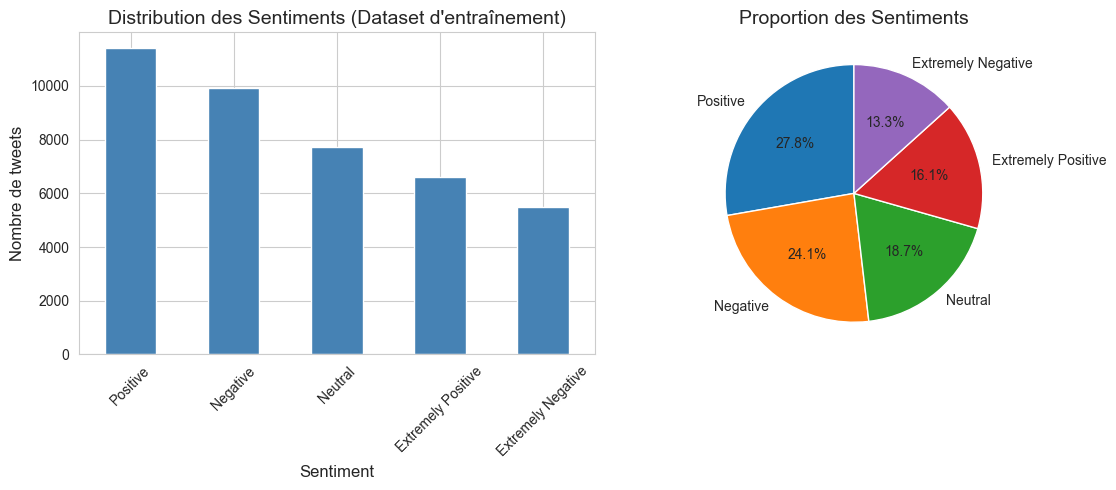

In [8]:
# Visualiser la distribution des sentiments
plt.figure(figsize=(12, 5))

# Graphique en barres
plt.subplot(1, 2, 1)
sentiment_counts.plot(kind='bar', color='steelblue')
plt.title('Distribution des Sentiments (Dataset d\'entraînement)', fontsize=14)
plt.xlabel('Sentiment', fontsize=12)
plt.ylabel('Nombre de tweets', fontsize=12)
plt.xticks(rotation=45)

# Graphique circulaire
plt.subplot(1, 2, 2)
sentiment_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Proportion des Sentiments', fontsize=14)
plt.ylabel('')

plt.tight_layout()
plt.show()

## 5. Analyse des tweets

In [9]:
# Vérifier les valeurs manquantes
print("Valeurs manquantes:")
print(train_df.isnull().sum())
print(f"\nPourcentage de valeurs manquantes dans OriginalTweet: {train_df['OriginalTweet'].isnull().sum() / len(train_df) * 100:.2f}%")

Valeurs manquantes:
UserName            0
ScreenName          0
Location         8590
TweetAt             0
OriginalTweet       0
Sentiment           0
dtype: int64

Pourcentage de valeurs manquantes dans OriginalTweet: 0.00%


In [10]:
# Supprimer les tweets vides si nécessaire
train_df_clean = train_df.dropna(subset=['OriginalTweet'])
print(f"Dataset après nettoyage: {len(train_df_clean)} tweets (supprimés: {len(train_df) - len(train_df_clean)})")

Dataset après nettoyage: 41157 tweets (supprimés: 0)


In [11]:
# Calculer la longueur des tweets (en caractères)
train_df_clean['tweet_length'] = train_df_clean['OriginalTweet'].astype(str).apply(len)

# Calculer le nombre de mots
train_df_clean['word_count'] = train_df_clean['OriginalTweet'].astype(str).apply(lambda x: len(x.split()))

print("Statistiques sur la longueur des tweets:")
print(f"Longueur moyenne: {train_df_clean['tweet_length'].mean():.2f} caractères")
print(f"Longueur médiane: {train_df_clean['tweet_length'].median():.0f} caractères")
print(f"Longueur min: {train_df_clean['tweet_length'].min()} caractères")
print(f"Longueur max: {train_df_clean['tweet_length'].max()} caractères")

print(f"\nNombre de mots moyen: {train_df_clean['word_count'].mean():.2f} mots")
print(f"Nombre de mots médian: {train_df_clean['word_count'].median():.0f} mots")

Statistiques sur la longueur des tweets:
Longueur moyenne: 204.20 caractères
Longueur médiane: 215 caractères
Longueur min: 11 caractères
Longueur max: 355 caractères

Nombre de mots moyen: 30.50 mots
Nombre de mots médian: 32 mots


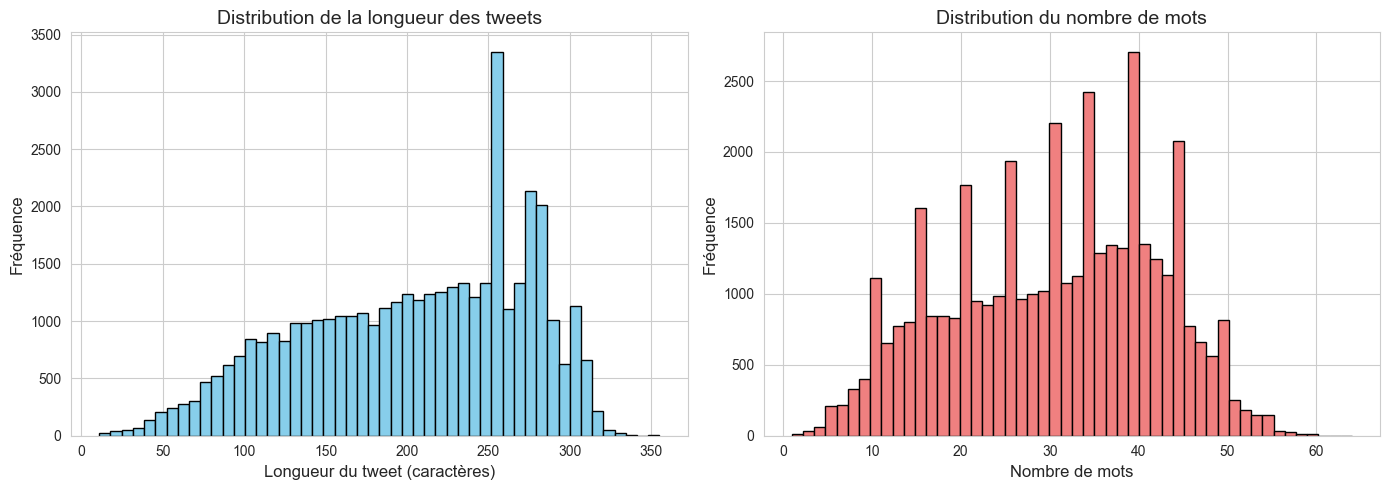

In [12]:
# Visualiser la distribution de la longueur des tweets
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.hist(train_df_clean['tweet_length'], bins=50, color='skyblue', edgecolor='black')
plt.xlabel('Longueur du tweet (caractères)', fontsize=12)
plt.ylabel('Fréquence', fontsize=12)
plt.title('Distribution de la longueur des tweets', fontsize=14)

plt.subplot(1, 2, 2)
plt.hist(train_df_clean['word_count'], bins=50, color='lightcoral', edgecolor='black')
plt.xlabel('Nombre de mots', fontsize=12)
plt.ylabel('Fréquence', fontsize=12)
plt.title('Distribution du nombre de mots', fontsize=14)

plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

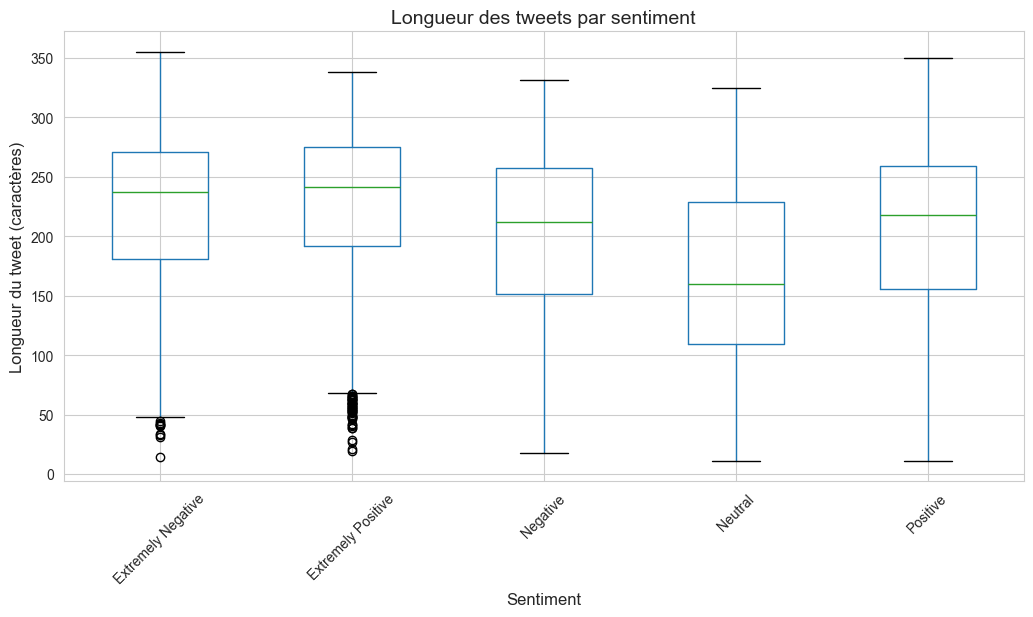

In [13]:
# Longueur des tweets par sentiment
plt.figure(figsize=(12, 6))
train_df_clean.boxplot(column='tweet_length', by='Sentiment', figsize=(12, 6))
plt.xlabel('Sentiment', fontsize=12)
plt.ylabel('Longueur du tweet (caractères)', fontsize=12)
plt.title('Longueur des tweets par sentiment', fontsize=14)
plt.suptitle('')
plt.xticks(rotation=45)
plt.show()

## 6. Exemples de tweets par sentiment

In [14]:
# Afficher quelques exemples pour chaque sentiment
print("Exemples de tweets par sentiment:\n")

for sentiment in train_df_clean['Sentiment'].unique():
    print(f"\n{'='*80}")
    print(f"Sentiment: {sentiment}")
    print(f"{'='*80}")
    examples = train_df_clean[train_df_clean['Sentiment'] == sentiment]['OriginalTweet'].head(3)
    for i, tweet in enumerate(examples, 1):
        print(f"\n{i}. {tweet}")
    print()

Exemples de tweets par sentiment:


Sentiment: Neutral

1. @MeNyrbie @Phil_Gahan @Chrisitv https://t.co/iFz9FAn2Pa and https://t.co/xX6ghGFzCC and https://t.co/I2NlzdxNo8

2. Was at the supermarket today. Didn't buy toilet paper. #Rebel

#toiletpapercrisis #covid_19 https://t.co/eVXkQLIdAZ

3. All month there hasn't been crowding in the supermarkets or restaurants, however reducing all the hours and closing the malls means everyone is now using the same entrance and dependent on a single supermarket. #manila #lockdown #covid2019 #Philippines https://t.co/HxWs9LAnF9


Sentiment: Positive

1. advice Talk to your neighbours family to exchange phone numbers create contact list with phone numbers of neighbours schools employer chemist GP set up online shopping accounts if poss adequate supplies of regular meds but not over order

2. Coronavirus Australia: Woolworths to give elderly, disabled dedicated shopping hours amid COVID-19 outbreak https://t.co/bInCA9Vp8P

3. My food stock is not the

## 7. Analyse des localisations

Top 10 des localisations les plus fréquentes:
Location
London             540
United States      528
London, England    520
New York, NY       395
Washington, DC     373
United Kingdom     337
Los Angeles, CA    281
India              268
UK                 232
Australia          225
Name: count, dtype: int64


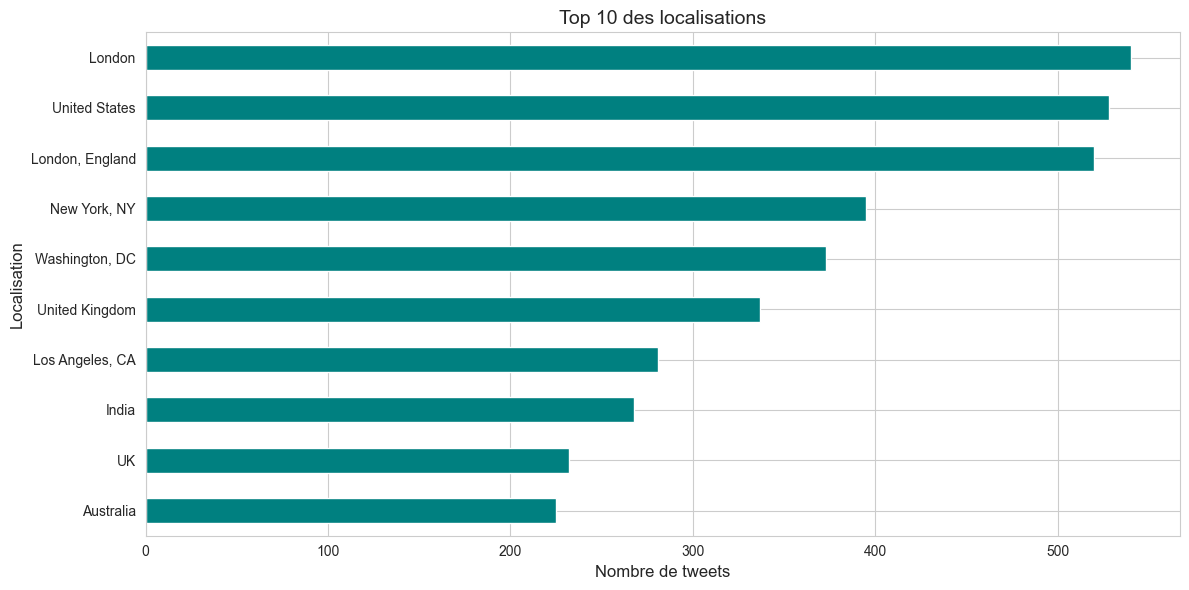

In [15]:
# Top 10 des localisations
print("Top 10 des localisations les plus fréquentes:")
top_locations = train_df_clean['Location'].value_counts().head(10)
print(top_locations)

plt.figure(figsize=(12, 6))
top_locations.plot(kind='barh', color='teal')
plt.xlabel('Nombre de tweets', fontsize=12)
plt.ylabel('Localisation', fontsize=12)
plt.title('Top 10 des localisations', fontsize=14)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 8. Analyse temporelle

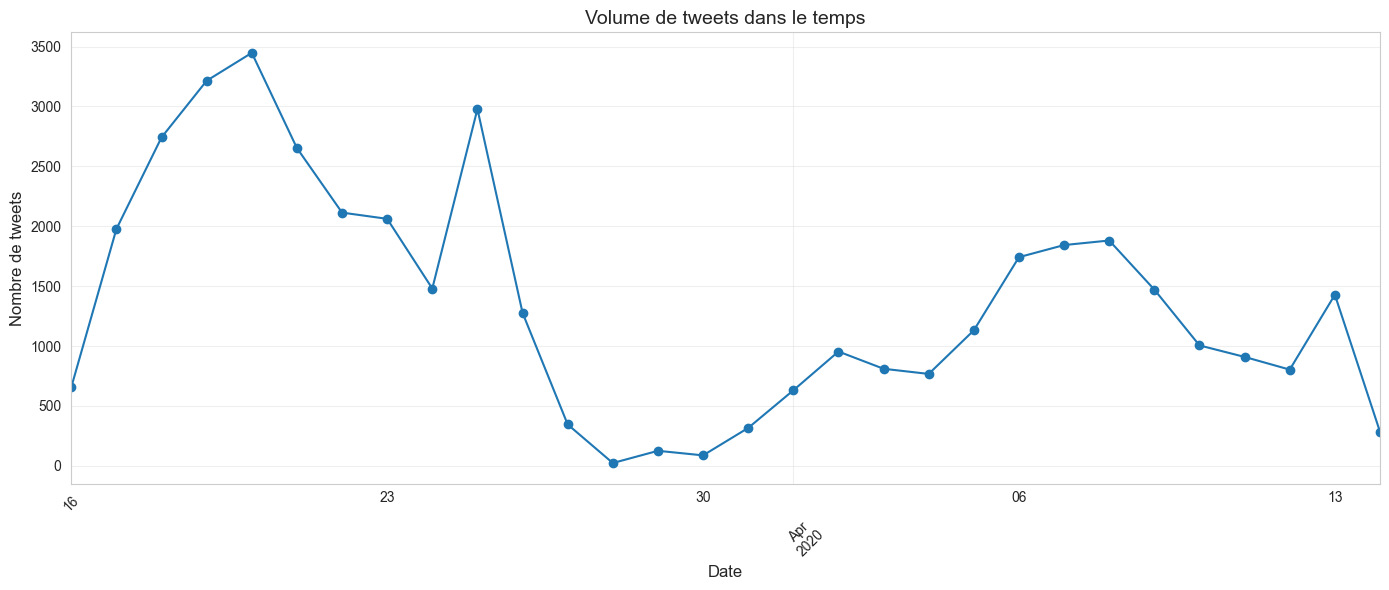

In [16]:
# Convertir les dates
train_df_clean['TweetAt'] = pd.to_datetime(train_df_clean['TweetAt'], format='%d-%m-%Y', errors='coerce')

# Distribution temporelle
plt.figure(figsize=(14, 6))
train_df_clean['TweetAt'].value_counts().sort_index().plot(kind='line', marker='o')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Nombre de tweets', fontsize=12)
plt.title('Volume de tweets dans le temps', fontsize=14)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Analyse du dataset de test

Distribution des sentiments dans le dataset de test:
Sentiment
Negative              1041
Positive               947
Neutral                619
Extremely Positive     599
Extremely Negative     592
Name: count, dtype: int64


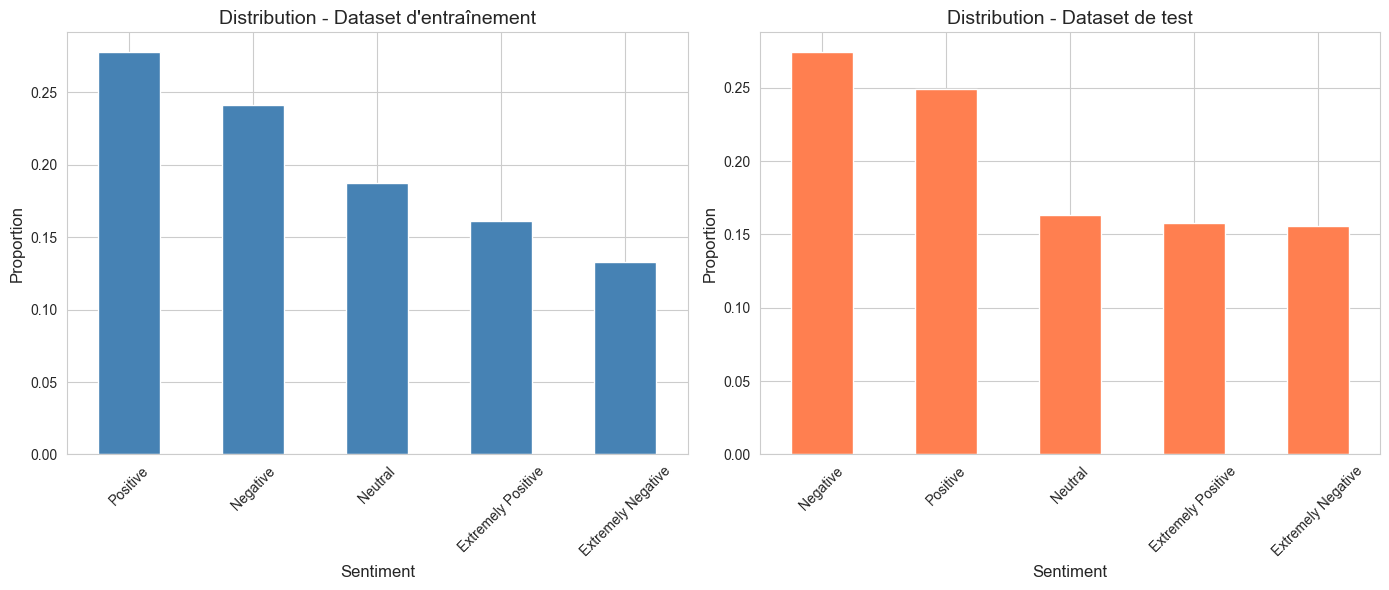

In [17]:
# Comparer les distributions train vs test
print("Distribution des sentiments dans le dataset de test:")
test_sentiment_counts = test_df['Sentiment'].value_counts()
print(test_sentiment_counts)

# Visualisation comparative
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
train_df['Sentiment'].value_counts(normalize=True).plot(kind='bar', color='steelblue')
plt.title('Distribution - Dataset d\'entraînement', fontsize=14)
plt.xlabel('Sentiment', fontsize=12)
plt.ylabel('Proportion', fontsize=12)
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
test_df['Sentiment'].value_counts(normalize=True).plot(kind='bar', color='coral')
plt.title('Distribution - Dataset de test', fontsize=14)
plt.xlabel('Sentiment', fontsize=12)
plt.ylabel('Proportion', fontsize=12)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 10. Résumé de l'exploration

In [20]:
print("="*80)
print("RÉSUMÉ DE L'EXPLORATION")
print("="*80)
print(f"\nDataset d'entraînement: {len(train_df_clean)} tweets")
print(f"Dataset de test: {len(test_df)} tweets")
print(f"\nNombre de classes de sentiment: {train_df_clean['Sentiment'].nunique()}")
print(f"Classes: {', '.join(train_df_clean['Sentiment'].unique())}")
print(f"\nLongueur moyenne des tweets: {train_df_clean['tweet_length'].mean():.2f} caractères")
print(f"Nombre moyen de mots: {train_df_clean['word_count'].mean():.2f} mots")
print(f"\nPériode couverte: du {train_df_clean['TweetAt'].min()} au {train_df_clean['TweetAt'].max()}")
print(f"\nValeurs manquantes: {train_df['OriginalTweet'].isnull().sum()} tweets")
print("\n" + "="*80)
print("PROCHAINES ÉTAPES:")
print("="*80)
print("1. Prétraitement des textes (nettoyage, tokenisation)")
print("2. Création des embeddings")
print("3. Construction du modèle (LSTM/GRU/Transformer)")
print("4. Entraînement et évaluation")
print("="*80)

RÉSUMÉ DE L'EXPLORATION

Dataset d'entraînement: 41157 tweets
Dataset de test: 3798 tweets

Nombre de classes de sentiment: 5
Classes: Neutral, Positive, Extremely Negative, Negative, Extremely Positive

Longueur moyenne des tweets: 204.20 caractères
Nombre moyen de mots: 30.50 mots

Période couverte: du 2020-03-16 00:00:00 au 2020-04-14 00:00:00

Valeurs manquantes: 0 tweets

PROCHAINES ÉTAPES:
1. Prétraitement des textes (nettoyage, tokenisation)
2. Création des embeddings
3. Construction du modèle (LSTM/GRU/Transformer)
4. Entraînement et évaluation
